# Twenty years of New York City street trees

New York City has counted its street trees three times, in 1995, 2005 and 2015, each time with volunteers and Parks
staff walking every block. This notebook compares the three, neighbourhood by neighbourhood: every live tree placed by
its own position into a 2010 Neighborhood Tabulation Area. The shapes in `data/geometry/` were made in
[Plotlay](https://www.getplotlay.com). It reads only `../data`.

What it measures is the trees each census recorded. The three censuses were run differently (1995 recorded positions
later, from addresses), so small differences in a neighbourhood can be method rather than trees.

In [1]:
import pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
DATA = '../data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
city = pd.read_csv(f'{DATA}/tables/citywide.csv').set_index('census')
city

,records,trees,trees_no_position,trees_area_from_census,trees_no_area,trees_in_parks_cemeteries_airports
census,,,,,,
1995,516989,482509,30193,15778,14478,2786
2005,592372,584252,8665,32,8715,1396
2015,683788,652173,0,85,0,6575


## 1. Citywide

In [2]:
t = city.trees
print(f"Live street trees: {t[1995]:,} in 1995, {t[2005]:,} in 2005, {t[2015]:,} in 2015")
print(f"1995 to 2015: {t[2015] - t[1995]:+,} ({t[2015] / t[1995] - 1:+.1%})")

Live street trees: 482,509 in 1995, 584,252 in 2005, 652,173 in 2015
1995 to 2015: +169,664 (+35.2%)


## 2. By borough

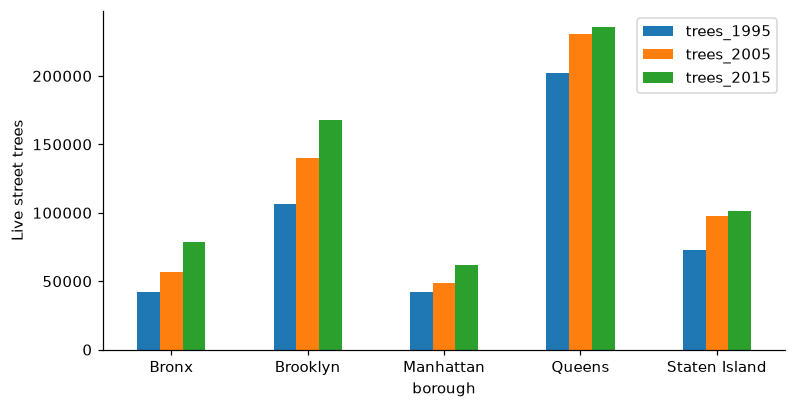

,trees_1995,trees_2005,trees_2015,change
borough,,,,
Bronx,41830.0,57070.0,78894.0,0.886
Brooklyn,106540.0,140041.0,167857.0,0.576
Manhattan,42289.0,49018.0,61483.0,0.454
Queens,201826.0,230417.0,235767.0,0.168
Staten Island,72631.0,97568.0,101443.0,0.397


In [3]:
ch = pd.read_csv(f'{DATA}/tables/change_1995_2015.csv')
b = ch.groupby('borough')[['trees_1995', 'trees_2005', 'trees_2015']].sum()
b['change'] = (b.trees_2015 / b.trees_1995 - 1).round(3)
ax = b[['trees_1995', 'trees_2005', 'trees_2015']].plot.bar(figsize=(8, 4), ylabel='Live street trees', rot=0); plt.show()
b

## 3. Neighbourhoods

In [4]:
print(len(ch), 'neighbourhoods;', (ch.change < 0).sum(), 'have fewer trees;', (ch.change_pct >= 100).sum(), 'at least doubled; median change', ch.change_pct.median(), '%')
ch.sort_values('change', ascending=False).head(8)[['name', 'borough', 'trees_1995', 'trees_2015', 'change', 'change_pct']]

188 neighbourhoods; 14 have fewer trees; 51 at least doubled; median change 44.3 %


,name,borough,trees_1995,trees_2015,change,change_pct
41,East New York,Brooklyn,2892.0,9162.0,6270.0,216.8
187,Great Kills,Staten Island,6893.0,10267.0,3374.0,48.9
63,Hunts Point,Bronx,325.0,3292.0,2967.0,912.9
174,Charleston-Richmond Valley-Tottenville,Staten Island,4964.0,7910.0,2946.0,59.3
28,Crown Heights North,Brooklyn,3386.0,6181.0,2795.0,82.5
38,Bushwick South,Brooklyn,1582.0,4334.0,2752.0,174.0
123,Far Rockaway-Bayswater,Queens,2090.0,4711.0,2621.0,125.4
181,Rossville-Woodrow,Staten Island,6219.0,8840.0,2621.0,42.1


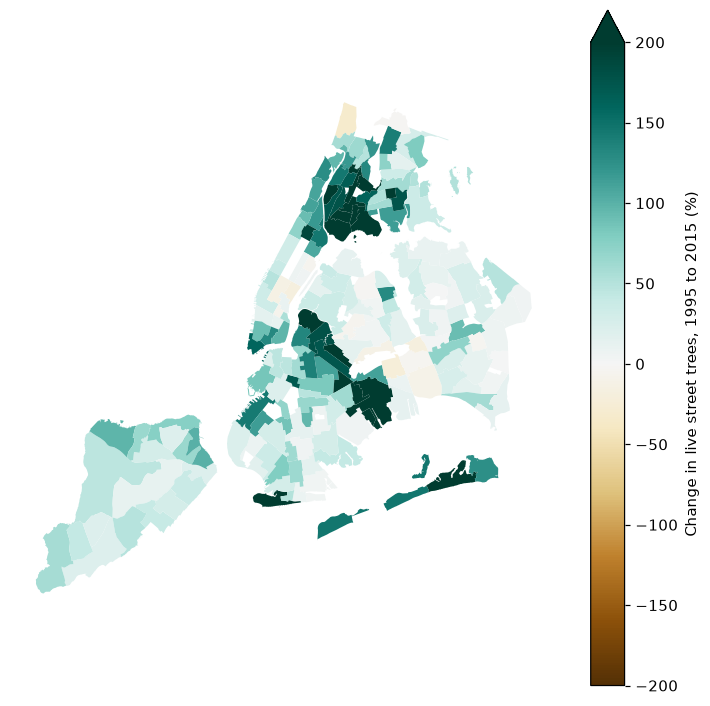

In [5]:
g = gpd.read_file(f'{DATA}/geometry/neighbourhoods.geojson').merge(ch[['nta', 'change_pct']], left_on='key', right_on='nta')
ax = g.to_crs(2263).plot(column='change_pct', cmap='BrBG', vmin=-200, vmax=200, legend=True, figsize=(8, 8), legend_kwds={'label': 'Change in live street trees, 1995 to 2015 (%)'})
ax.set_axis_off(); plt.show()

## 4. East New York, tree by tree

census
1995     5289
2005     6717
2015    15402
dtype: int64


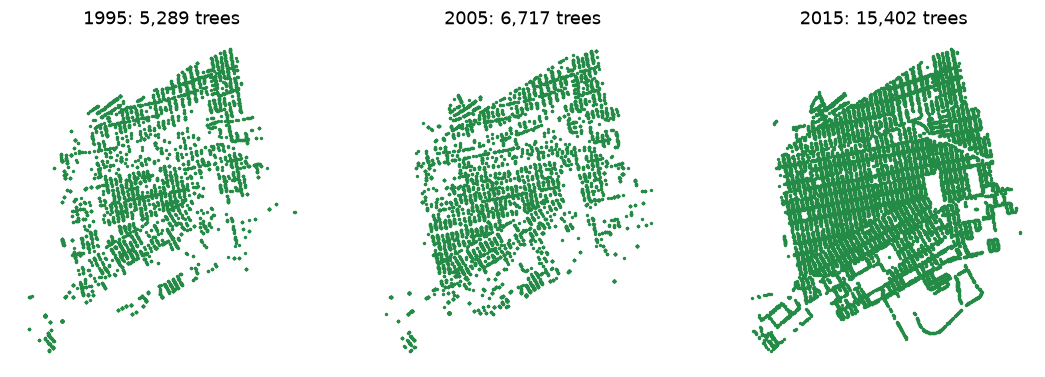

In [6]:
e = pd.read_csv(f'{DATA}/trees/east_new_york_trees.csv')
print(e.groupby('census').size())
fig, axs = plt.subplots(1, 3, figsize=(12, 4.4), sharex=True, sharey=True)
for ax, y in zip(axs, (1995, 2005, 2015)):
    s = e[e.census == y]; ax.scatter(s.lng, s.lat, s=1.5, c='#238b45'); ax.set_title(f'{y}: {len(s):,} trees'); ax.set_axis_off(); ax.set_aspect(1.32)
plt.show()

## 5. Species

In [7]:
sp = pd.read_csv(f'{DATA}/tables/species.csv').set_index('species')
sp[['share_1995', 'share_2005', 'share_2015']]

,share_1995,share_2005,share_2015
species,,,
London planetree,18.1,15.3,13.3
Honeylocust,6.9,8.9,9.9
Callery pear,6.4,10.8,9.0
Pin oak,7.5,7.5,8.2
Norway maple,22.2,12.7,5.2
Cherry,0.3,1.7,4.6
Littleleaf linden,5.4,4.7,4.6
Japanese zelkova,1.2,2.5,4.5


## Read it carefully

- **A tree is a live record.** Dead trees, stumps, shafts and planting spaces are left out of every census.
- **Placed by position.** Each tree goes to the neighbourhood its latitude and longitude fall in. Trees a census could
  not place go to the area the census named, or count only citywide (`citywide.csv` says how many).
- **The neighbourhoods are 2010's**, dissolved from the 2010 census tracts; parks, cemeteries and airports are left out
  of the map, and the few trees in them count only citywide.